# Sliding-window Transformer with KV caching

GQA, RoPE, RMSNorm, SwiGLU, shared embeddings and local causal attention. 

Default: 12 layers, width 512, 8 query heads, 2 KV heads, window 256. Approximately 50.75M parameters with a 10,000-token vocabulary. Query blocks compute only nearby scores: attention work is O(nwd), with a constant overhead from query blocking; projections and the FFN are additional work. Actual speed depends on the GPU.

Training uses gradient accumulation. Generation supports greedy, temperature and top-k decoding with bounded K/V storage and absolute RoPE positions. References: https://arxiv.org/abs/2310.06825 and https://aclanthology.org/2023.emnlp-main.298/ .

## 1. Hugging Face Login

In [1]:
import os
from huggingface_hub import login
from kaggle_secrets import UserSecretsClient

user_secrets = UserSecretsClient()
HF_TOKEN = user_secrets.get_secret("HF_TOKEN")
os.environ["HF_TOKEN"] = HF_TOKEN
login(token=HF_TOKEN)

print("Hugging Face login successful.")

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


Hugging Face login successful.


## 2. Check GPU

In [2]:
import torch

print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())
for i in range(torch.cuda.device_count()):
    print(f"GPU {i}:", torch.cuda.get_device_name(i))

CUDA available: True
GPU count: 2
GPU 0: Tesla T4
GPU 1: Tesla T4


## 3. Configuration

In [3]:
import os
import random
import json
import time
import math
import zipfile
import shutil

# Hugging Face dataset
HF_DATASET_REPO = "Exploration-Lab/CS-781-Capstone"

# You can use any of the 4 train files or all the files for pre-training the legal model
TRAIN_FILE = ("Phase_1_Pretraining/Train/train_acts.json",
             "Phase_1_Pretraining/Train/train_high_courts.json",
             "Phase_1_Pretraining/Train/train_supreme_court.json",
             "Phase_1_Pretraining/Train/train_tribunals.json")
TEST_FILE = "Phase_1_Pretraining/Test/test.json"

# Training configuration
VAL_TOKENS = 500_000
TRAIN_BLOCK_SIZE = 1024
SEED = 42
random.seed(SEED)
MODEL_CONTEXT_LENGTH = 1024
N_EMBD = 512
N_LAYER = 12
N_HEAD = 8

# Generation
TARGET_GENERATION_WORDS = 128
MAX_GENERATION_TOKENS = 4096
TEMPERATURE = 1.0

# Kaggle output
OUTPUT_DIR = "/kaggle/working/cs781_phase1_sliding_window"
MODEL_OUTPUT_DIR = os.path.join(
    OUTPUT_DIR,
    "legal-window-gqa-final"
)
PREDICTION_PATH = os.path.join(
    OUTPUT_DIR,
    "prediction.json"
)
SUBMISSION_ZIP = os.path.join(
    OUTPUT_DIR,
    "submission.zip"
)
LOSS_PLOT_PATH = os.path.join(
    OUTPUT_DIR,
    "training_validation_loss.png"
)
os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)
print("Configuration loaded.")
N_KV_HEAD = 2
FFN_DIM = 2048
WINDOW_SIZE = 256
QUERY_CHUNK_SIZE = 128
TRAIN_BATCH_SIZE = 16
GRAD_ACCUM_STEPS = 1
USE_TWO_GPUS = False  # Optional DataParallel for training only.

Configuration loaded.


## 4. Load Tokenizer

In [ ]:
from collections import defaultdict, Counter
import heapq

SPECIALS = ["<pad>", "<unk>", "<s>", "</s>"]

class BytelevelBPE:

    def __init__(self, vocab_size=5000):
        self.vocab_size = vocab_size
        self.specials = SPECIALS.copy()
        self.byte_vocab = [str(i) for i in range(256)]
        self.merges = []
        self.merge_ranks = {}
        self.vocab = []
        self.stoi = {}
        self.itos = {}
        # Maps each BPE symbol to the bytes represented by it
        self.symbol_to_bytes = {}
    
    # 1. WORD -> UTF-8 BYTE SYMBOLS

    def word_to_symbols(self, word):
        byte_seq = word.encode("utf-8")
        return [str(b) for b in byte_seq] + ["</w>"]

    # 2. BUILD WORD FREQUENCIES

    def build_word_freqs(self, corpus):
        word_counter = Counter()
        print("Building word frequencies...")
        for text in corpus:
            if not isinstance(text, str):
                continue

            word_counter.update(text.split())
        print(
            f"Unique whitespace-separated words: "
            f"{len(word_counter):,}"
        )
        # Convert each unique word to byte symbols only once
        word_freqs = {}

        for word, freq in word_counter.items():
            symbols = tuple(self.word_to_symbols(word))
            word_freqs[symbols] = (
                word_freqs.get(symbols, 0) + freq
            )

        return word_freqs


    # 3. PAIRS OCCURRING IN ONE WORD

    @staticmethod
    def get_pairs(symbols):
        return {
            (symbols[i], symbols[i + 1])
            for i in range(len(symbols) - 1)
        }

    # 4. COUNT PAIR OCCURRENCES IN ONE WORD

    @staticmethod
    def pair_counts_in_word(symbols):
        counts = Counter()
        for i in range(len(symbols) - 1):
            counts[
                (symbols[i], symbols[i + 1])
            ] += 1

        return counts

    # 5. MERGE A PAIR INSIDE ONE WORD

    @staticmethod
    def merge_symbols(symbols, pair, merged_symbol):
        new_symbols = []
        i = 0
        while i < len(symbols):
            if (
                i < len(symbols) - 1
                and symbols[i] == pair[0]
                and symbols[i + 1] == pair[1]
            ):
                new_symbols.append(merged_symbol)
                i += 2
            else:
                new_symbols.append(symbols[i])
                i += 1

        return tuple(new_symbols)

    # 6. TRAIN OPTIMIZED BPE

    def train(self, corpus):
        word_freqs = self.build_word_freqs(corpus)
        vocab = (
            self.specials
            + self.byte_vocab
            + ["</w>"]
        )
        seen = set(vocab)
        for b in range(256):
            self.symbol_to_bytes[str(b)] = bytes([b])
        self.symbol_to_bytes["</w>"] = b""

        words = []
        frequencies = []
        for symbols, freq in word_freqs.items():
            words.append(symbols)
            frequencies.append(freq)
        del word_freqs

        pair_counts = defaultdict(int)
        pair_to_words = defaultdict(set)

        print("Building initial pair statistics...")

        for word_id, symbols in enumerate(words):
            freq = frequencies[word_id]
            local_counts = self.pair_counts_in_word(symbols)
            for pair, count in local_counts.items():
                pair_counts[pair] += count * freq
                pair_to_words[pair].add(word_id)

        print(
            f"Initial unique pairs: "
            f"{len(pair_counts):,}"
        )

        # MAX HEAP
        #
        # Python has min-heap, so use negative frequency.
        #
        # We keep stale entries and validate them when popped.
        # This avoids rebuilding the heap after every merge.

        heap = []
        for pair, count in pair_counts.items():
            heapq.heappush(heap,(-count, pair))
        target_merges = max(0,self.vocab_size - len(vocab))
        print(f"Target merges: {target_merges:,}")
        while (len(vocab) < self.vocab_size and heap):
            while heap:
                neg_count, pair = heapq.heappop(heap)
                heap_count = -neg_count
                current_count = pair_counts.get(pair,0)
                # Ignore stale heap entries
                if (current_count == heap_count and current_count > 0):
                    break
            else:
                break

            max_freq = pair_counts.get(pair, 0)

            # Same stopping condition as before
            if max_freq <= 1:
                break

            # Create collision-free merged symbol
            merged_symbol = (f"<bpe_{len(self.merges)}>")

            # Byte representation of new symbol
            left_bytes = self.symbol_to_bytes[pair[0]]
            right_bytes = self.symbol_to_bytes[pair[1]]
            self.symbol_to_bytes[merged_symbol] = left_bytes + right_bytes

            self.merges.append(pair)
            self.merge_ranks[pair] = (len(self.merges) - 1,merged_symbol)
            if merged_symbol not in seen:
                seen.add(merged_symbol)
                vocab.append(merged_symbol)

            # ----------------------------------------------------
            # IMPORTANT OPTIMIZATION
            #
            # Only process words containing selected pair.
            # ----------------------------------------------------

            affected_word_ids = list(pair_to_words.get(pair, set()))
            changed_pairs = set()
            for word_id in affected_word_ids:
                old_symbols = words[word_id]
                freq = frequencies[word_id]
                # Pair may have disappeared because of an earlier
                # update involving this word
                if pair not in self.get_pairs(old_symbols):
                    continue
                
                # Statistics BEFORE merge
                old_counts = self.pair_counts_in_word(old_symbols)

                # Merge selected pair
                new_symbols = self.merge_symbols(old_symbols,pair,merged_symbol)
                if new_symbols == old_symbols:
                    continue

                # Statistics AFTER merge
                new_counts = self.pair_counts_in_word(new_symbols)

                # Save updated word
                words[word_id] = new_symbols

                all_pairs = (
                    set(old_counts)
                    | set(new_counts)
                )

                # Update only pairs affected by this word

                for p in all_pairs:

                    old_n = old_counts.get(p, 0)
                    new_n = new_counts.get(p, 0)
                    delta = (
                        new_n - old_n
                    ) * freq

                    if delta != 0:
                        pair_counts[p] += delta
                        changed_pairs.add(p)

                    # Update inverted index
                    if new_n > 0:
                        pair_to_words[p].add(word_id)
                    else:
                        pair_to_words[p].discard(word_id)

            # Selected pair should now be gone from affected words
            pair_to_words[pair].clear()

            # Push updated frequencies into heap
            for p in changed_pairs:
                count = pair_counts.get(p, 0)
                if count > 0:
                    heapq.heappush(heap,(-count, p))

        self.vocab = vocab
        self.vocab_size = len(vocab)
        self.stoi = {
            symbol: i
            for i, symbol in enumerate(vocab)
        }

        self.itos = {
            i: symbol
            for symbol, i in self.stoi.items()
        }

        print("\nTokenizer training complete.")

        print(
            "Final vocabulary size:",
            self.vocab_size
        )

        print(
            "Number of merges:",
            len(self.merges)
        )

    # 7. APPLY BPE TO ONE WORD

    def apply_bpe(self, word):
        symbols = self.word_to_symbols(word)
        while len(symbols) > 1:
            best_pair = None
            best_rank = float("inf")
            best_merged_symbol = None

            for i in range(len(symbols) - 1):
                pair = (symbols[i],symbols[i + 1])
                merge_info = self.merge_ranks.get(pair)
                if merge_info is not None:
                    rank, merged_symbol = merge_info
                    if rank < best_rank:
                        best_rank = rank
                        best_pair = pair
                        best_merged_symbol = merged_symbol

            if best_pair is None:
                break

            symbols = list(
                self.merge_symbols(
                    tuple(symbols),
                    best_pair,
                    best_merged_symbol
                )
            )

        return symbols

    # 8. ENCODE

    def encode(self,text,add_bos=False,add_eos=False):
        ids = []
        if add_bos:
            ids.append(
                self.stoi["<s>"]
            )

        for word in text.split():
            symbols = self.apply_bpe(word)
            for symbol in symbols:
                ids.append(
                    self.stoi.get(
                        symbol,
                        self.stoi["<unk>"]
                    )
                )

        if add_eos:
            ids.append(
                self.stoi["</s>"]
            )

        return ids

    # 9. DECODE

    def decode(self, ids):

        words = []
        current_bytes = bytearray()

        for token_id in ids:
            symbol = self.itos.get(token_id)
            if symbol is None:
                continue
            if symbol in self.specials:
                continue

            # Determine whether this token ends a word
            ends_word = self._symbol_ends_word(symbol)
            byte_value = self.symbol_to_bytes.get(symbol, b"")
            current_bytes.extend(byte_value)

            if ends_word:
                try:
                    word = bytes(current_bytes).decode("utf-8")
                    words.append(word)
                except UnicodeDecodeError:
                    words.append("<unk>")
                current_bytes = bytearray()

        # Remaining bytes
        if current_bytes:
            try:
                words.append(bytes(current_bytes).decode("utf-8"))
            except UnicodeDecodeError:
                words.append("<unk>")

        return " ".join(words)

    # 10. CHECK WHETHER SYMBOL CONTAINS </w> AT END

    def _symbol_ends_word(self, symbol):
        if symbol == "</w>":
            return True
        # Find merge that created this symbol
        for pair, (_, merged) in self.merge_ranks.items():
            if merged == symbol:
                return self._symbol_ends_word(
                    pair[1]
                )

        return False

    # 11. VOCAB SIZE

    def get_vocab_size(self):
        return len(self.vocab)

## 5. Download Training Data From Hugging Face

In [5]:
from huggingface_hub import hf_hub_download

train_file_path_acts = hf_hub_download(
    repo_id=HF_DATASET_REPO,
    filename=TRAIN_FILE[0],
    repo_type="dataset",
    token=HF_TOKEN
)

train_file_path_high_courts = hf_hub_download(
    repo_id=HF_DATASET_REPO,
    filename=TRAIN_FILE[1],
    repo_type="dataset",
    token=HF_TOKEN
)

train_file_path_supreme_court = hf_hub_download(
    repo_id=HF_DATASET_REPO,
    filename=TRAIN_FILE[2],
    repo_type="dataset",
    token=HF_TOKEN
)

train_file_path_tribunals = hf_hub_download(
    repo_id=HF_DATASET_REPO,
    filename=TRAIN_FILE[3],
    repo_type="dataset",
    token=HF_TOKEN
)

print("Training file:")
print(train_file_path_acts)

print("Training file:")
print(train_file_path_high_courts)

print("Training file:")
print(train_file_path_supreme_court)

print("Training file:")
print(train_file_path_tribunals)

Phase_1_Pretraining/Train/train_acts.jso(…): reconstructing file:   0%|          |  0.00B /  729MB            

Phase_1_Pretraining/Train/train_acts.jso(…): downloading bytes:           |  0.00B            

Phase_1_Pretraining/Train/train_high_cou(…): reconstructing file:   0%|          |  0.00B / 10.7GB            

Phase_1_Pretraining/Train/train_high_cou(…): downloading bytes:           |  0.00B            

Phase_1_Pretraining/Train/train_supreme_(…): reconstructing file:   0%|          |  0.00B / 1.32GB            

Phase_1_Pretraining/Train/train_supreme_(…): downloading bytes:           |  0.00B            

Phase_1_Pretraining/Train/train_tribunal(…): reconstructing file:   0%|          |  0.00B / 6.48GB            

Phase_1_Pretraining/Train/train_tribunal(…): downloading bytes:           |  0.00B            

Training file:
/root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/89edba6a44d6bb9593fd13b6895b5cd3b06eb82e/Phase_1_Pretraining/Train/train_acts.json
Training file:
/root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/89edba6a44d6bb9593fd13b6895b5cd3b06eb82e/Phase_1_Pretraining/Train/train_high_courts.json
Training file:
/root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/89edba6a44d6bb9593fd13b6895b5cd3b06eb82e/Phase_1_Pretraining/Train/train_supreme_court.json
Training file:
/root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/89edba6a44d6bb9593fd13b6895b5cd3b06eb82e/Phase_1_Pretraining/Train/train_tribunals.json


In [6]:
def load_json(path):
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)

In [7]:
source_paths = {
    "acts": train_file_path_acts,
    "high_courts": train_file_path_high_courts,
    "supreme_court": train_file_path_supreme_court,
    "tribunals": train_file_path_tribunals,
}

In [8]:
import os
import json
import random
import hashlib
import numpy as np

SOURCE_RATIOS = {
    "acts": 1,
    "high_courts": 2,
    "supreme_court": 1,
    "tribunals": 1,
}

TOKENIZER_WORD_BUDGET = 4_000_000
TRAIN_TOKEN_BUDGET = 400_000_000
VAL_TOKEN_BUDGET = VAL_TOKENS  # 500,000 in your configuration

# Use your chosen document-level validation fraction.
VALIDATION_FRACTION = 0.05

def allocate_budget(total):
    ratio_sum = sum(SOURCE_RATIOS.values())

    budgets = {
        name: total * ratio // ratio_sum
        for name, ratio in SOURCE_RATIOS.items()
    }

    # Handle rounding for budgets not divisible by five.
    remainder = total - sum(budgets.values())
    for name in list(budgets)[:remainder]:
        budgets[name] += 1

    return budgets

word_budgets = allocate_budget(TOKENIZER_WORD_BUDGET)
train_budgets = allocate_budget(TRAIN_TOKEN_BUDGET)
val_budgets = allocate_budget(VAL_TOKEN_BUDGET)

print("Tokenizer words:", word_budgets)
print("Training tokens:", train_budgets)
print("Validation tokens:", val_budgets)

Tokenizer words: {'acts': 800000, 'high_courts': 1600000, 'supreme_court': 800000, 'tribunals': 800000}
Training tokens: {'acts': 80000000, 'high_courts': 160000000, 'supreme_court': 80000000, 'tribunals': 80000000}
Validation tokens: {'acts': 100000, 'high_courts': 200000, 'supreme_court': 100000, 'tribunals': 100000}


In [9]:
%pip install -q ijson

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 149.9/149.9 kB 5.2 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


In [10]:
import os
import json
import hashlib
import sqlite3
import ijson

SPLIT_DIR = os.path.join(OUTPUT_DIR, "document_splits")
os.makedirs(SPLIT_DIR, exist_ok=True)

DEDUP_PATH = os.path.join(SPLIT_DIR, "dedup.sqlite")

# Rebuild from scratch when this cell is rerun.
if os.path.exists(DEDUP_PATH):
    os.remove(DEDUP_PATH)

connection = sqlite3.connect(DEDUP_PATH)
connection.execute(
    "CREATE TABLE seen (digest BLOB PRIMARY KEY) WITHOUT ROWID"
)


class JsonlTexts:
    """Reads texts from disk; each iteration starts from the beginning."""

    def __init__(self, path):
        self.path = path

    def __iter__(self):
        with open(self.path, "r", encoding="utf-8") as f:
            for line in f:
                yield json.loads(line)


train_sources = {}
val_sources = {}
split_counts = {}

try:
    for name, source_path in source_paths.items():
        train_path = os.path.join(SPLIT_DIR, f"{name}_train.jsonl")
        val_path = os.path.join(SPLIT_DIR, f"{name}_val.jsonl")

        counts = {
            "train": 0,
            "validation": 0,
            "invalid": 0,
            "duplicates": 0,
        }

        print(f"\nStreaming {name}...", flush=True)

        with (
            open(source_path, "rb") as source,
            open(train_path, "w", encoding="utf-8") as train_out,
            open(val_path, "w", encoding="utf-8") as val_out,
        ):
            # Verify the top-level structure without loading the file.
            first = source.read(1)
            while first and first.isspace():
                first = source.read(1)

            if first != b"[":
                raise ValueError(f"{name}: expected a top-level JSON list.")

            source.seek(0)

            for index, record in enumerate(
                ijson.items(source, "item"), start=1
            ):
                text = (
                    record.get("text")
                    if isinstance(record, dict)
                    else None
                )

                if not isinstance(text, str) or not text.strip():
                    counts["invalid"] += 1
                    continue

                text = " ".join(text.split())
                digest = hashlib.sha256(text.encode("utf-8")).digest()

                cursor = connection.execute(
                    "INSERT OR IGNORE INTO seen VALUES (?)",
                    (digest,),
                )

                if cursor.rowcount == 0:
                    counts["duplicates"] += 1
                    continue

                # Deterministic document-level split.
                split_digest = hashlib.sha256(
                    str(SEED).encode("ascii") + digest
                ).digest()

                fraction = (
                    int.from_bytes(split_digest[:8], "big") / (1 << 64)
                )

                if fraction < VALIDATION_FRACTION:
                    destination = val_out
                    counts["validation"] += 1
                else:
                    destination = train_out
                    counts["train"] += 1

                destination.write(
                    json.dumps(text, ensure_ascii=False) + "\n"
                )

                if index % 10_000 == 0:
                    connection.commit()

        connection.commit()

        train_sources[name] = JsonlTexts(train_path)
        val_sources[name] = JsonlTexts(val_path)
        split_counts[name] = counts

        print(name, counts, flush=True)

finally:
    connection.close()


Streaming acts...
acts {'train': 17775, 'validation': 956, 'invalid': 4, 'duplicates': 91}

Streaming high_courts...
high_courts {'train': 2297028, 'validation': 121220, 'invalid': 0, 'duplicates': 118490}

Streaming supreme_court...
supreme_court {'train': 52572, 'validation': 2789, 'invalid': 21, 'duplicates': 167}

Streaming tribunals...
tribunals {'train': 820769, 'validation': 43429, 'invalid': 0, 'duplicates': 4934}


In [11]:
def select_word_budget(documents, target_words, source_name):
    selected = []
    collected = 0

    for text in documents:
        remaining = target_words - collected

        if remaining == 0:
            break

        words = text.split()

        if len(words) <= remaining:
            selected.append(text)
            collected += len(words)
        else:
            selected.append(" ".join(words[:remaining]))
            collected += remaining

    if collected != target_words:
        raise ValueError(
            f"{source_name}: needs {target_words:,} words, "
            f"but only {collected:,} are available in its training split."
        )

    return selected

tokenizer_corpus = []

for name, budget in word_budgets.items():
    selected = select_word_budget(
        train_sources[name], budget, name
    )
    tokenizer_corpus.extend(selected)

    print(f"{name}: {budget:,} words")
    del selected

random.Random(SEED).shuffle(tokenizer_corpus)

print("Tokenizer corpus documents:", len(tokenizer_corpus))

acts: 800,000 words
high_courts: 1,600,000 words
supreme_court: 800,000 words
tribunals: 800,000 words
Tokenizer corpus documents: 3777


In [12]:
BPE_VOCAB_SIZE = 10000

# Always create a fresh instance when retraining.
tokenizer = BytelevelBPE(vocab_size=BPE_VOCAB_SIZE)
tokenizer.train(tokenizer_corpus)


examples = [
    "Section 12(1): The Court dismissed the appeal.",
    "भारत का सर्वोच्च न्यायालय",
    "₹500 — café",
    "Multiple   spaces\nand\ttabs",
]

for text in examples:
    ids = tokenizer.encode(text)


print("Tokenizer prepared.")
print("Actual vocabulary:", tokenizer.get_vocab_size())

del tokenizer_corpus

Building word frequencies...
Unique whitespace-separated words: 124,937
Building initial pair statistics...
Initial unique pairs: 5,262
Target merges: 9,739

Tokenizer training complete.
Final vocabulary size: 10000
Number of merges: 9739
Tokenizer prepared.
Actual vocabulary: 10000


## 6. Create Train and Validation Tokens Set

In [13]:
def write_token_mixture(sources, budgets, output_path):
    total_tokens = sum(budgets.values())

    token_array = np.memmap(
        output_path,
        dtype=np.uint32,
        mode="w+",
        shape=(total_tokens,),
    )

    eos_id = tokenizer.stoi["</s>"]
    vocab_size = tokenizer.get_vocab_size()

    position = 0
    source_ranges = {}

    try:
        for name, target in budgets.items():
            start = position
            written = 0
            documents_used = 0

            print(f"\nEncoding {name}: target {target:,} tokens")

            for text in sources[name]:
                remaining = target - written

                if remaining == 0:
                    break

                ids = tokenizer.encode(text)
                ids.append(eos_id)

                # The final document may be truncated at the token budget.
                chunk = ids[:remaining]

                if not all(0 <= token_id < vocab_size for token_id in chunk):
                    raise ValueError(f"{name}: invalid token ID.")

                count = len(chunk)
                token_array[position:position + count] = np.asarray(
                    chunk, dtype=np.uint32
                )

                position += count
                written += count
                documents_used += 1

            if written != target:
                raise ValueError(
                    f"{name}: needs {target:,} tokens, "
                    f"but only {written:,} are available. "
                    "No documents were repeated."
                )

            source_ranges[name] = {
                "start": start,
                "end": position,
                "tokens": written,
                "documents_used": documents_used,
            }

            print(f"Finished {name}: {written:,} tokens")

        token_array.flush()

    except Exception:
        del token_array
        if os.path.exists(output_path):
            os.remove(output_path)
        raise

    del token_array
    return source_ranges


TRAIN_IDS_PATH = os.path.join(OUTPUT_DIR, "train_ids.uint32")
VAL_IDS_PATH = os.path.join(OUTPUT_DIR, "val_ids.uint32")

train_ranges = write_token_mixture(
    train_sources, train_budgets, TRAIN_IDS_PATH
)

val_ranges = write_token_mixture(
    val_sources, val_budgets, VAL_IDS_PATH
)


Encoding acts: target 80,000,000 tokens
Finished acts: 80,000,000 tokens

Encoding high_courts: target 160,000,000 tokens
Finished high_courts: 160,000,000 tokens

Encoding supreme_court: target 80,000,000 tokens
Finished supreme_court: 80,000,000 tokens

Encoding tribunals: target 80,000,000 tokens
Finished tribunals: 80,000,000 tokens

Encoding acts: target 100,000 tokens
Finished acts: 100,000 tokens

Encoding high_courts: target 200,000 tokens
Finished high_courts: 200,000 tokens

Encoding supreme_court: target 100,000 tokens
Finished supreme_court: 100,000 tokens

Encoding tribunals: target 100,000 tokens
Finished tribunals: 100,000 tokens


In [14]:
train_ids = np.memmap(
    TRAIN_IDS_PATH, dtype=np.uint32, mode="r"
)

val_ids = np.memmap(
    VAL_IDS_PATH, dtype=np.uint32, mode="r"
)


metadata = {
    "seed": SEED,
    "source_ratios": SOURCE_RATIOS,
    "validation_document_fraction": VALIDATION_FRACTION,
    "tokenizer_training_words": TOKENIZER_WORD_BUDGET,
    "vocab_size": tokenizer.get_vocab_size(),
    "dtype": "uint32",
    "train": train_ranges,
    "validation": val_ranges,
}

with open(
    os.path.join(OUTPUT_DIR, "data_metadata.json"),
    "w",
    encoding="utf-8",
) as f:
    json.dump(metadata, f, indent=2)

print("Training tokens:", f"{len(train_ids):,}")
print("Validation tokens:", f"{len(val_ids):,}")
print("First IDs:", train_ids[:20])

Training tokens: 400,000,000
Validation tokens: 500,000
First IDs: [3991 4204 8644 5132 5905 2129   44 6505  293 5260  477 5106  608 5976
   44 3430  557  460  469  276]


## 7. Create Token Blocks
The training/evaluation functions perform the next-token shift exactly once. Blocks are drawn from the concatenated token stream and may span document boundaries; EOS separates documents. This preserves the reference's data convention rather than the previous document-safe block dataset.

In [15]:
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader


class TokenDataset(Dataset):
    def __init__(self, path, seq_len):
        self.path = path
        self.seq_len = seq_len
        self.ids = np.memmap(path, dtype=np.uint32, mode="r")

    def __len__(self):
        return len(self.ids) // self.seq_len

    def __getitem__(self, idx):
        start = idx * self.seq_len

        # Copy only this block and convert to torch.long.
        input_ids = torch.from_numpy(
            np.array(
                self.ids[start:start + self.seq_len],
                dtype=np.int64,
                copy=True,
            )
        )

        return {
            "input_ids": input_ids,
            "labels": input_ids.clone(),
        }

## 8. Create Datasets

In [16]:
train_dataset = TokenDataset(TRAIN_IDS_PATH, TRAIN_BLOCK_SIZE)
val_dataset = TokenDataset(VAL_IDS_PATH, TRAIN_BLOCK_SIZE)

In [17]:
# Batch size 1 is only for checking the data pipeline.
check_loader = DataLoader(
    train_dataset,
    batch_size=1,
    shuffle=True,
    num_workers=0,
)

batch = next(iter(check_loader))

print("Training blocks:", len(train_dataset))
print("Validation blocks:", len(val_dataset))
print("Input shape:", batch["input_ids"].shape)
print("Label shape:", batch["labels"].shape)
print("Dtype:", batch["input_ids"].dtype)

Training blocks: 390625
Validation blocks: 488
Input shape: torch.Size([1, 1024])
Label shape: torch.Size([1, 1024])
Dtype: torch.int64


## 9. Define The Model

In [ ]:
import math
from dataclasses import dataclass, asdict
import torch
import torch.nn as nn
import torch.nn.functional as F

@dataclass
class WindowConfig:
    vocab_size: int
    pad_id: int
    d_model: int = 512
    n_layers: int = 12
    n_heads: int = 8
    n_kv_heads: int = 2
    d_ff: int = 2048
    max_seq_len: int = 1024  # Maximum training chunk, not a generation position limit.
    window_size: int = 256
    query_chunk_size: int = 128
    dropout: float = 0.1
    rope_base: float = 10000.0

class RMSNorm(nn.Module):
    def __init__(self, width, eps=1e-6):
        super().__init__()
        self.weight = nn.Parameter(torch.ones(width))
        self.eps = eps

    def forward(self, x):
        # Compute the mean square in float32 for numerical stability.
        normalized = x.float() * torch.rsqrt(x.float().square().mean(-1, keepdim=True) + self.eps)
        return normalized.to(x.dtype) * self.weight

class RotaryPositions(nn.Module):
    def __init__(self, head_dim, base):
        super().__init__()
        inv_freq = 1.0 / (base ** (torch.arange(0, head_dim, 2).float() / head_dim))
        self.register_buffer('inv_freq', inv_freq)

    def forward(self, x, positions):
        # x: [B, heads, T, head_dim]. Rotate neighboring even/odd features.
        with torch.autocast(device_type=x.device.type, enabled=False):
            angles = positions.float()[:, None] * self.inv_freq.float()[None, :]
            cos = angles.cos()[None, None].to(x.dtype)
            sin = angles.sin()[None, None].to(x.dtype)
        even, odd = x[..., 0::2], x[..., 1::2]
        return torch.stack((even*cos - odd*sin, even*sin + odd*cos), dim=-1).flatten(-2)

class SlidingWindowGQA(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.head_dim = cfg.d_model // cfg.n_heads
        self.n_heads = cfg.n_heads
        self.n_kv_heads = cfg.n_kv_heads
        self.group_size = cfg.n_heads // cfg.n_kv_heads
        self.window = cfg.window_size
        self.chunk_size = min(cfg.query_chunk_size, cfg.window_size)
        self.q_proj = nn.Linear(cfg.d_model, cfg.d_model, bias=False)
        self.k_proj = nn.Linear(cfg.d_model, cfg.n_kv_heads*self.head_dim, bias=False)
        self.v_proj = nn.Linear(cfg.d_model, cfg.n_kv_heads*self.head_dim, bias=False)
        self.out_proj = nn.Linear(cfg.d_model, cfg.d_model, bias=False)
        self.rope = RotaryPositions(self.head_dim, cfg.rope_base)
        self.dropout = nn.Dropout(cfg.dropout)

    def forward(self, x, positions, key_valid, past=None, use_cache=False):
        b, t, _ = x.shape
        q = self.q_proj(x).view(b,t,self.n_heads,self.head_dim).transpose(1,2)
        k = self.k_proj(x).view(b,t,self.n_kv_heads,self.head_dim).transpose(1,2)
        v = self.v_proj(x).view(b,t,self.n_kv_heads,self.head_dim).transpose(1,2)
        q, k = self.rope(q,positions), self.rope(k,positions)
        past_length = 0 if past is None else past[0].size(2)
        if past is not None:
            k = torch.cat([past[0],k],dim=2)
            v = torch.cat([past[1],v],dim=2)
        q = q.reshape(b,self.n_kv_heads,self.group_size,t,self.head_dim)
        outputs = []
        # Process blocks of queries against ONLY the nearby keys.
        # A score block has at most chunk_size x (window + chunk_size - 1) entries.
        for start in range(0,t,self.chunk_size):
            end = min(start+self.chunk_size,t)
            left = max(0,past_length+start-self.window+1)
            right = past_length+end
            local_k, local_v = k[:,:,left:right], v[:,:,left:right]
            query_index = torch.arange(past_length+start,past_length+end,device=x.device)
            key_index = torch.arange(left,right,device=x.device)
            visible = (key_index[None,:] <= query_index[:,None]) & (
                key_index[None,:] > query_index[:,None]-self.window)
            allowed = visible[None] & key_valid[:,None,left:right]
            # Right-padded query rows can have no real keys in their window.
            # Give only those ignored rows a fallback key to avoid NaN softmax.
            fallback = torch.zeros_like(allowed)
            fallback[:,:,0] = ~allowed.any(dim=-1)
            allowed = allowed | fallback
            with torch.autocast(device_type=x.device.type,enabled=False):
                scores = torch.einsum('bgrtd,bgsd->bgrts',q[:,:,:,start:end].float(),local_k.float())
                scores = scores / math.sqrt(self.head_dim)
                weights = scores.masked_fill(~allowed[:,None,None],float('-inf')).softmax(-1)
            context = torch.einsum('bgrts,bgsd->bgrtd',self.dropout(weights.to(v.dtype)),local_v)
            outputs.append(context)
        context = torch.cat(outputs,dim=3).reshape(b,self.n_heads,t,self.head_dim)
        context = context.transpose(1,2).contiguous().view(b,t,-1)
        new_cache = None
        if use_cache:
            keep = self.window-1
            new_cache = (k[:,:,-keep:].clone(),v[:,:,-keep:].clone()) if keep else (k[:,:,:0].clone(),v[:,:,:0].clone())
        return self.out_proj(context), new_cache

In [19]:
class SwiGLU(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.gate = nn.Linear(cfg.d_model, cfg.d_ff, bias=False)
        self.up = nn.Linear(cfg.d_model, cfg.d_ff, bias=False)
        self.down = nn.Linear(cfg.d_ff, cfg.d_model, bias=False)

    def forward(self, x):
        return self.down(F.silu(self.gate(x)) * self.up(x))

class DecoderBlock(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.norm1 = RMSNorm(cfg.d_model)
        self.norm2 = RMSNorm(cfg.d_model)
        self.attention = SlidingWindowGQA(cfg)
        self.ffn = SwiGLU(cfg)
        self.dropout = nn.Dropout(cfg.dropout)

    def forward(self, x, positions, key_valid, past=None, use_cache=False):
        attended, cache = self.attention(self.norm1(x), positions, key_valid, past, use_cache)
        x = x + self.dropout(attended)
        x = x + self.dropout(self.ffn(self.norm2(x)))
        return x, cache

class WindowGQALM(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.cfg = cfg
        if (cfg.d_model % cfg.n_heads or cfg.n_heads % cfg.n_kv_heads
                or (cfg.d_model//cfg.n_heads) % 2 or cfg.window_size < 1
                or cfg.query_chunk_size < 1):
            raise ValueError('Check head dimensions, window size and query chunk size')
        self.embedding = nn.Embedding(cfg.vocab_size, cfg.d_model, padding_idx=cfg.pad_id)
        self.dropout = nn.Dropout(cfg.dropout)
        self.blocks = nn.ModuleList([DecoderBlock(cfg) for _ in range(cfg.n_layers)])
        self.final_norm = RMSNorm(cfg.d_model)
        self.lm_head = nn.Linear(cfg.d_model, cfg.vocab_size, bias=False)
        self.apply(self.initialize)
        # Tie AFTER initialization so the shared parameter is initialized once.
        self.lm_head.weight = self.embedding.weight
        with torch.no_grad():
            self.embedding.weight[cfg.pad_id].zero_()
        for block in self.blocks:
            nn.init.normal_(block.attention.out_proj.weight, std=0.02/math.sqrt(2*cfg.n_layers))
            nn.init.normal_(block.ffn.down.weight, std=0.02/math.sqrt(2*cfg.n_layers))

    @staticmethod
    def initialize(module):
        if isinstance(module, (nn.Linear, nn.Embedding)):
            nn.init.normal_(module.weight, std=0.02)

    def forward(self, ids, cache=None, use_cache=False, last_only=False):
        if ids.ndim != 2 or ids.size(1) == 0:
            raise ValueError('Use nonempty [batch, time] token IDs')
        if cache is not None and not use_cache:
            raise ValueError('A cache requires use_cache=True')
        if use_cache and self.training:
            raise ValueError('Call eval() before cached generation')
        if self.training and ids.size(1) > self.cfg.max_seq_len:
            raise ValueError('Training batch exceeds configured sequence length')
        # Absolute RoPE offset is independent of the bounded cache length.
        offset = 0 if cache is None else cache['position']
        positions = torch.arange(offset,offset+ids.size(1),device=ids.device)
        valid = ids.ne(self.cfg.pad_id)
        if cache is not None:
            valid = torch.cat([cache['valid'],valid],dim=1)
        x = self.dropout(self.embedding(ids))
        updated = []
        for index, block in enumerate(self.blocks):
            previous = None if cache is None else cache['kv'][index]
            x, new_kv = block(x,positions,valid,previous,use_cache)
            if use_cache: updated.append(new_kv)
        logits = self.lm_head(self.final_norm(x[:, -1:] if last_only else x))
        if use_cache:
            keep = self.cfg.window_size-1
            return logits, {'kv':updated,
                'valid':valid[:,-keep:].clone() if keep else valid[:,:0].clone(),
                'position':offset+ids.size(1)}
        return logits

## 10. Training Arguments
The batch size is set in Configuration. Effective example batch size is `TRAIN_BATCH_SIZE * GRAD_ACCUM_STEPS`. With DataParallel the configured batch is the total across GPUs, not a per-GPU batch.

Local attention computes 128-query blocks against at most 383 nearby keys for a 256-token window. It does not allocate a full n-by-n score matrix first. Each layer retains at most 255 old K/V positions during generation; a separate counter tracks absolute RoPE position.

In [20]:
import torch.nn.functional as F
from torch.utils.data import DataLoader

def unwrap_model(model):
    return model.module if isinstance(model, torch.nn.DataParallel) else model

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.manual_seed(SEED)
cfg = WindowConfig(
    vocab_size=tokenizer.get_vocab_size(), pad_id=tokenizer.stoi['<pad>'],
    d_model=N_EMBD, n_layers=N_LAYER, n_heads=N_HEAD, n_kv_heads=N_KV_HEAD,
    d_ff=FFN_DIM, max_seq_len=TRAIN_BLOCK_SIZE, window_size=WINDOW_SIZE,
    query_chunk_size=QUERY_CHUNK_SIZE, dropout=0.1,
)
model = WindowGQALM(cfg).to(device)
if USE_TWO_GPUS and torch.cuda.device_count() >= 2:
    model = torch.nn.DataParallel(model, device_ids=[0, 1])
base_model = unwrap_model(model)
print(f'{sum(p.numel() for p in model.parameters()):,} parameters')
print('Effective batch:', TRAIN_BATCH_SIZE * GRAD_ACCUM_STEPS)

train_loader = DataLoader(train_dataset, batch_size=TRAIN_BATCH_SIZE,
    shuffle=True, num_workers=0, pin_memory=device.type == 'cuda')
val_loader = DataLoader(val_dataset, batch_size=TRAIN_BATCH_SIZE,
    shuffle=False, num_workers=0, pin_memory=device.type == 'cuda')
os.makedirs(MODEL_OUTPUT_DIR, exist_ok=True)

50,745,856 parameters
Effective batch: 16


In [21]:
# Optional: compare full-sequence and cached logits across window eviction.
# This tiny model does not modify the training model.
RUN_CACHE_CHECK = False
if RUN_CACHE_CHECK:
    with torch.random.fork_rng(devices=[]), torch.no_grad():
        tiny_cfg = WindowConfig(vocab_size=32,pad_id=0,d_model=16,n_layers=2,
            n_heads=4,n_kv_heads=2,d_ff=32,window_size=4,query_chunk_size=2,dropout=0)
        tiny = WindowGQALM(tiny_cfg).eval()
        ids = torch.tensor([[2,4,5,6,7,8,9,10,11]])
        full = tiny(ids)
        cache = None
        pieces = []
        for start,end in [(0,3),(3,4),(4,7),(7,9)]:
            logits,cache = tiny(ids[:,start:end],cache=cache,use_cache=True)
            pieces.append(logits)
        torch.testing.assert_close(full,torch.cat(pieces,dim=1),atol=1e-5,rtol=1e-4)
        print('Cache check passed:',cache['valid'].size(1),'retained positions;',cache['position'],'seen')
        del tiny,full,cache,pieces,logits

## 11. Training

In [22]:
@torch.no_grad()
def evaluate_validation(model, val_loader, device):
    was_training = model.training
    model.eval()

    total_nll = 0.0
    total_targets = 0

    for batch in val_loader:
        x = batch["input_ids"].to(device)
        labels = batch["labels"].to(device)
        targets = labels[:, 1:]

        with torch.autocast(
            device_type=device.type,
            dtype=torch.float16,
            enabled=device.type == "cuda",
        ):
            logits = model(x)

            loss_mean = F.cross_entropy(
                logits[:, :-1, :].reshape(-1, logits.size(-1)),
                targets.reshape(-1),
            )

        count = targets.numel()
        total_nll += loss_mean.item() * count
        total_targets += count

    if total_targets == 0:
        raise ValueError("Validation loader is empty.")

    val_loss = total_nll / total_targets
    val_ppl = math.exp(val_loss) if val_loss < 700 else float("inf")

    model.train(was_training)
    return val_loss, val_ppl

In [23]:
from dataclasses import asdict

def train_model(model, train_loader, val_loader, train_steps, lr,
                accumulation_steps=8, log_every=100, eval_every=1000):
    if len(train_loader) == 0 or min(train_steps, accumulation_steps, log_every, eval_every) < 1:
        raise ValueError('Use a nonempty loader and positive steps/intervals.')
    base_model = unwrap_model(model)
    device = next(base_model.parameters()).device
    use_amp = device.type == 'cuda'
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    scaler = torch.amp.GradScaler('cuda', enabled=use_amp)
    optimizer.zero_grad(set_to_none=True)
    os.makedirs(MODEL_OUTPUT_DIR, exist_ok=True)
    best_path = os.path.join(MODEL_OUTPUT_DIR, 'best.pt')
    latest_path = os.path.join(MODEL_OUTPUT_DIR, 'latest.pt')
    loss_history, step_history, validation_history = [], [], []
    best_val_loss = float('inf')
    optimizer_steps = skipped_updates = 0
    interval_nll = interval_targets = pending_targets = pending_batches = 0
    tokens_seen = 0
    validation_due = False
    iterator = iter(train_loader)
    # A fixed scale keeps each backward loss manageable. Actual token counts
    # are used to normalize gradients just before the optimizer update.
    reference_tokens = train_loader.batch_size * (base_model.cfg.max_seq_len-1) * accumulation_steps

    def save_atomic(state, path):
        torch.save(state, path+'.tmp')
        os.replace(path+'.tmp', path)

    model.train()
    started = time.time()
    for step in range(1, train_steps+1):
        try:
            batch = next(iterator)
        except StopIteration:
            iterator = iter(train_loader)
            batch = next(iterator)
        x = batch['input_ids'].to(device, non_blocking=True)
        labels = batch['labels'].to(device, non_blocking=True)
        targets = labels[:,1:]
        count = targets.numel()
        with torch.autocast(device_type=device.type,dtype=torch.float16,enabled=use_amp):
            logits = model(x)
            loss_sum = F.cross_entropy(logits[:,:-1,:].reshape(-1,logits.size(-1)),
                                       targets.reshape(-1), reduction='sum')
        if not torch.isfinite(loss_sum):
            raise RuntimeError(f'Non-finite loss at batch {step}')
        scaler.scale(loss_sum/reference_tokens).backward()
        interval_nll += loss_sum.detach().item()
        interval_targets += count
        pending_targets += count
        pending_batches += 1
        tokens_seen += count
        del x, labels, targets, logits, loss_sum
        if step == 1 or step % log_every == 0 or step == train_steps:
            average_loss = interval_nll/interval_targets
            loss_history.append(average_loss)
            step_history.append(step)
            print(f'Batch {step}/{train_steps} | Average train loss={average_loss:.4f}',flush=True)
            interval_nll = interval_targets = 0
        validation_due |= step % eval_every == 0

        if pending_batches == accumulation_steps or step == train_steps:
            scaler.unscale_(optimizer)
            for parameter in model.parameters():
                if parameter.grad is not None:
                    parameter.grad.mul_(reference_tokens/pending_targets)
            torch.nn.utils.clip_grad_norm_(model.parameters(),1.0)
            previous_scale = scaler.get_scale()
            scaler.step(optimizer)
            scaler.update()
            if scaler.get_scale() < previous_scale:
                skipped_updates += 1
            else:
                optimizer_steps += 1
            optimizer.zero_grad(set_to_none=True)
            pending_targets = pending_batches = 0

            if validation_due or step == train_steps:
                val_loss,val_ppl = evaluate_validation(model,val_loader,device)
                validation_history.append(dict(step=step,optimizer_steps=optimizer_steps,
                    val_loss=val_loss,val_ppl=val_ppl))
                state = dict(model_config=asdict(base_model.cfg),
                    model_state_dict=base_model.state_dict(),step=step,val_loss=val_loss)
                if val_loss < best_val_loss:
                    best_val_loss = val_loss
                    save_atomic(state,best_path)
                state.update(optimizer_state_dict=optimizer.state_dict(),
                    scaler_state_dict=scaler.state_dict(),optimizer_steps=optimizer_steps,
                    skipped_updates=skipped_updates,best_val_loss=best_val_loss,
                    accumulation_steps=accumulation_steps,tokens_seen=tokens_seen)
                save_atomic(state,latest_path)
                with open(os.path.join(MODEL_OUTPUT_DIR,'history.json'),'w') as f:
                    json.dump(dict(train_steps=step_history,train_losses=loss_history,
                        validation=validation_history,tokens_seen=tokens_seen),f,indent=2)
                print(f'Updates={optimizer_steps} | Validation loss={val_loss:.4f} | Perplexity={val_ppl:.2f}',flush=True)
                validation_due = False
                model.train()
    checkpoint = torch.load(best_path,map_location='cpu',weights_only=True)
    base_model.load_state_dict(checkpoint['model_state_dict'])
    model.eval()
    print(f'Target tokens: {tokens_seen:,}; updates: {optimizer_steps}; AMP skips: {skipped_updates}')
    print(f'Training including validation: {(time.time()-started)/60:.1f} minutes')
    return loss_history,step_history,validation_history

In [24]:
TRAIN_STEPS = 30000
LEARNING_RATE = 3e-4

loss_history, step_history, validation_history = train_model(
    model, train_loader, val_loader,
    train_steps=TRAIN_STEPS, lr=LEARNING_RATE,
    accumulation_steps=GRAD_ACCUM_STEPS,
    log_every=100, eval_every=1000,
)

Batch 1/30000 | Average train loss=9.2978
Batch 100/30000 | Average train loss=6.8775
Batch 200/30000 | Average train loss=5.6035
Batch 300/30000 | Average train loss=4.8904
Batch 400/30000 | Average train loss=4.4489
Batch 500/30000 | Average train loss=4.1468
Batch 600/30000 | Average train loss=3.9090
Batch 700/30000 | Average train loss=3.7553
Batch 800/30000 | Average train loss=3.6119
Batch 900/30000 | Average train loss=3.5353
Batch 1000/30000 | Average train loss=3.5058
Updates=1000 | Validation loss=3.5105 | Perplexity=33.47
Batch 1100/30000 | Average train loss=3.4016
Batch 1200/30000 | Average train loss=3.3427
Batch 1300/30000 | Average train loss=3.2631
Batch 1400/30000 | Average train loss=3.2191
Batch 1500/30000 | Average train loss=3.1764
Batch 1600/30000 | Average train loss=3.1591
Batch 1700/30000 | Average train loss=3.1146
Batch 1800/30000 | Average train loss=3.0983
Batch 1900/30000 | Average train loss=3.0275
Batch 2000/30000 | Average train loss=3.0034
Updates=20

## 12. Perplexity

In [25]:
# Use the full val_loader, not the two-batch sample-check list.
val_loss, val_perplexity = evaluate_validation(
    model=model,
    val_loader=val_loader,
    device=device,
)

print(f"Validation loss: {val_loss:.6f}")
print(f"Validation perplexity: {val_perplexity:.2f}")

Validation loss: 2.176911
Validation perplexity: 8.82


## 13. Plot Training and Validation Loss

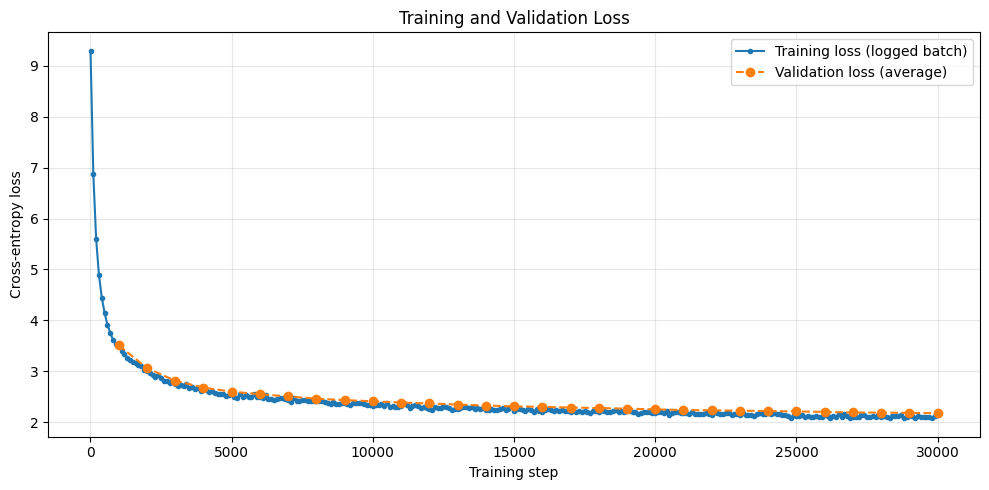

Plot saved: /kaggle/working/cs781_phase1_sliding_window/training_validation_loss.png


In [26]:
import matplotlib.pyplot as plt

val_steps = [record["step"] for record in validation_history]
val_losses = [record["val_loss"] for record in validation_history]

fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    step_history,
    loss_history,
    marker=".",
    label="Training loss (logged batch)",
)

ax.plot(
    val_steps,
    val_losses,
    marker="o",
    linestyle="--",
    label="Validation loss (average)",
)

ax.set_xlabel("Training step")
ax.set_ylabel("Cross-entropy loss")
ax.set_title("Training and Validation Loss")
ax.grid(alpha=0.3)
ax.legend()

fig.tight_layout()
fig.savefig(LOSS_PLOT_PATH, dpi=200)
plt.show()

print("Plot saved:", LOSS_PLOT_PATH)

## 14. Save Final Model to Kaggle Output

In [27]:
from dataclasses import asdict
import os
import torch

base_model = (
    model.module
    if isinstance(model, torch.nn.DataParallel)
    else model
)

os.makedirs(MODEL_OUTPUT_DIR, exist_ok=True)

model_path = os.path.join(MODEL_OUTPUT_DIR, "model.pt")

torch.save(
    {
        "model_config": asdict(base_model.cfg),
        "model_state_dict": {
            name: tensor.detach().cpu()
            for name, tensor in base_model.state_dict().items()
        },
    },
    model_path,
)

print("Model saved:", model_path)

Model saved: /kaggle/working/cs781_phase1_sliding_window/legal-window-gqa-final/model.pt


In [28]:
import os
import json

os.makedirs(MODEL_OUTPUT_DIR, exist_ok=True)

tokenizer_state = {
    "vocab_size": tokenizer.get_vocab_size(),
    "specials": tokenizer.specials,
    "vocab": tokenizer.vocab,
    "merges": [list(pair) for pair in tokenizer.merges],
    "merge_ranks": [
        {
            "pair": list(pair),
            "rank": rank,
            "merged_symbol": merged_symbol,
        }
        for pair, (rank, merged_symbol)
        in tokenizer.merge_ranks.items()
    ],
    "symbol_to_bytes": {
        symbol: list(value)
        for symbol, value in tokenizer.symbol_to_bytes.items()
    },
}

tokenizer_path = os.path.join(MODEL_OUTPUT_DIR, "tokenizer.json")
temporary_path = tokenizer_path + ".tmp"

with open(temporary_path, "w", encoding="utf-8") as f:
    json.dump(tokenizer_state, f, ensure_ascii=False)

os.replace(temporary_path, tokenizer_path)

print("Tokenizer saved:", tokenizer_path)

Tokenizer saved: /kaggle/working/cs781_phase1_sliding_window/legal-window-gqa-final/tokenizer.json


In [29]:
architecture_source = "import math\nfrom dataclasses import dataclass, asdict\nimport torch\nimport torch.nn as nn\nimport torch.nn.functional as F\n\n@dataclass\nclass WindowConfig:\n    vocab_size: int\n    pad_id: int\n    d_model: int = 512\n    n_layers: int = 12\n    n_heads: int = 8\n    n_kv_heads: int = 2\n    d_ff: int = 2048\n    max_seq_len: int = 1024  # Maximum training chunk, not a generation position limit.\n    window_size: int = 256\n    query_chunk_size: int = 128\n    dropout: float = 0.1\n    rope_base: float = 10000.0\n\nclass RMSNorm(nn.Module):\n    def __init__(self, width, eps=1e-6):\n        super().__init__()\n        self.weight = nn.Parameter(torch.ones(width))\n        self.eps = eps\n\n    def forward(self, x):\n        # Compute the mean square in float32 for numerical stability.\n        normalized = x.float() * torch.rsqrt(x.float().square().mean(-1, keepdim=True) + self.eps)\n        return normalized.to(x.dtype) * self.weight\n\nclass RotaryPositions(nn.Module):\n    def __init__(self, head_dim, base):\n        super().__init__()\n        inv_freq = 1.0 / (base ** (torch.arange(0, head_dim, 2).float() / head_dim))\n        self.register_buffer('inv_freq', inv_freq)\n\n    def forward(self, x, positions):\n        # x: [B, heads, T, head_dim]. Rotate neighboring even/odd features.\n        with torch.autocast(device_type=x.device.type, enabled=False):\n            angles = positions.float()[:, None] * self.inv_freq.float()[None, :]\n            cos = angles.cos()[None, None].to(x.dtype)\n            sin = angles.sin()[None, None].to(x.dtype)\n        even, odd = x[..., 0::2], x[..., 1::2]\n        return torch.stack((even*cos - odd*sin, even*sin + odd*cos), dim=-1).flatten(-2)\n\nclass SlidingWindowGQA(nn.Module):\n    def __init__(self, cfg):\n        super().__init__()\n        self.head_dim = cfg.d_model // cfg.n_heads\n        self.n_heads = cfg.n_heads\n        self.n_kv_heads = cfg.n_kv_heads\n        self.group_size = cfg.n_heads // cfg.n_kv_heads\n        self.window = cfg.window_size\n        self.chunk_size = min(cfg.query_chunk_size, cfg.window_size)\n        self.q_proj = nn.Linear(cfg.d_model, cfg.d_model, bias=False)\n        self.k_proj = nn.Linear(cfg.d_model, cfg.n_kv_heads*self.head_dim, bias=False)\n        self.v_proj = nn.Linear(cfg.d_model, cfg.n_kv_heads*self.head_dim, bias=False)\n        self.out_proj = nn.Linear(cfg.d_model, cfg.d_model, bias=False)\n        self.rope = RotaryPositions(self.head_dim, cfg.rope_base)\n        self.dropout = nn.Dropout(cfg.dropout)\n\n    def forward(self, x, positions, key_valid, past=None, use_cache=False):\n        b, t, _ = x.shape\n        q = self.q_proj(x).view(b,t,self.n_heads,self.head_dim).transpose(1,2)\n        k = self.k_proj(x).view(b,t,self.n_kv_heads,self.head_dim).transpose(1,2)\n        v = self.v_proj(x).view(b,t,self.n_kv_heads,self.head_dim).transpose(1,2)\n        q, k = self.rope(q,positions), self.rope(k,positions)\n        past_length = 0 if past is None else past[0].size(2)\n        if past is not None:\n            k = torch.cat([past[0],k],dim=2)\n            v = torch.cat([past[1],v],dim=2)\n        q = q.reshape(b,self.n_kv_heads,self.group_size,t,self.head_dim)\n        outputs = []\n        # Process blocks of queries against ONLY the nearby keys.\n        # A score block has at most chunk_size x (window + chunk_size - 1) entries.\n        for start in range(0,t,self.chunk_size):\n            end = min(start+self.chunk_size,t)\n            left = max(0,past_length+start-self.window+1)\n            right = past_length+end\n            local_k, local_v = k[:,:,left:right], v[:,:,left:right]\n            query_index = torch.arange(past_length+start,past_length+end,device=x.device)\n            key_index = torch.arange(left,right,device=x.device)\n            visible = (key_index[None,:] <= query_index[:,None]) & (\n                key_index[None,:] > query_index[:,None]-self.window)\n            allowed = visible[None] & key_valid[:,None,left:right]\n            # Right-padded query rows can have no real keys in their window.\n            # Give only those ignored rows a fallback key to avoid NaN softmax.\n            fallback = torch.zeros_like(allowed)\n            fallback[:,:,0] = ~allowed.any(dim=-1)\n            allowed = allowed | fallback\n            with torch.autocast(device_type=x.device.type,enabled=False):\n                scores = torch.einsum('bgrtd,bgsd->bgrts',q[:,:,:,start:end].float(),local_k.float())\n                scores = scores / math.sqrt(self.head_dim)\n                weights = scores.masked_fill(~allowed[:,None,None],float('-inf')).softmax(-1)\n            context = torch.einsum('bgrts,bgsd->bgrtd',self.dropout(weights.to(v.dtype)),local_v)\n            outputs.append(context)\n        context = torch.cat(outputs,dim=3).reshape(b,self.n_heads,t,self.head_dim)\n        context = context.transpose(1,2).contiguous().view(b,t,-1)\n        new_cache = None\n        if use_cache:\n            # Keep w-1 previous tokens; the next token supplies the w-th key.\n            # clone releases the larger prefill storage instead of retaining a view.\n            keep = self.window-1\n            new_cache = (k[:,:,-keep:].clone(),v[:,:,-keep:].clone()) if keep else (k[:,:,:0].clone(),v[:,:,:0].clone())\n        return self.out_proj(context), new_cache\n\nclass SwiGLU(nn.Module):\n    def __init__(self, cfg):\n        super().__init__()\n        self.gate = nn.Linear(cfg.d_model, cfg.d_ff, bias=False)\n        self.up = nn.Linear(cfg.d_model, cfg.d_ff, bias=False)\n        self.down = nn.Linear(cfg.d_ff, cfg.d_model, bias=False)\n\n    def forward(self, x):\n        return self.down(F.silu(self.gate(x)) * self.up(x))\n\nclass DecoderBlock(nn.Module):\n    def __init__(self, cfg):\n        super().__init__()\n        self.norm1 = RMSNorm(cfg.d_model)\n        self.norm2 = RMSNorm(cfg.d_model)\n        self.attention = SlidingWindowGQA(cfg)\n        self.ffn = SwiGLU(cfg)\n        self.dropout = nn.Dropout(cfg.dropout)\n\n    def forward(self, x, positions, key_valid, past=None, use_cache=False):\n        attended, cache = self.attention(self.norm1(x), positions, key_valid, past, use_cache)\n        x = x + self.dropout(attended)\n        x = x + self.dropout(self.ffn(self.norm2(x)))\n        return x, cache\n\nclass WindowGQALM(nn.Module):\n    def __init__(self, cfg):\n        super().__init__()\n        self.cfg = cfg\n        if (cfg.d_model % cfg.n_heads or cfg.n_heads % cfg.n_kv_heads\n                or (cfg.d_model//cfg.n_heads) % 2 or cfg.window_size < 1\n                or cfg.query_chunk_size < 1):\n            raise ValueError('Check head dimensions, window size and query chunk size')\n        self.embedding = nn.Embedding(cfg.vocab_size, cfg.d_model, padding_idx=cfg.pad_id)\n        self.dropout = nn.Dropout(cfg.dropout)\n        self.blocks = nn.ModuleList([DecoderBlock(cfg) for _ in range(cfg.n_layers)])\n        self.final_norm = RMSNorm(cfg.d_model)\n        self.lm_head = nn.Linear(cfg.d_model, cfg.vocab_size, bias=False)\n        self.apply(self.initialize)\n        # Tie AFTER initialization so the shared parameter is initialized once.\n        self.lm_head.weight = self.embedding.weight\n        with torch.no_grad():\n            self.embedding.weight[cfg.pad_id].zero_()\n        for block in self.blocks:\n            nn.init.normal_(block.attention.out_proj.weight, std=0.02/math.sqrt(2*cfg.n_layers))\n            nn.init.normal_(block.ffn.down.weight, std=0.02/math.sqrt(2*cfg.n_layers))\n\n    @staticmethod\n    def initialize(module):\n        if isinstance(module, (nn.Linear, nn.Embedding)):\n            nn.init.normal_(module.weight, std=0.02)\n\n    def forward(self, ids, cache=None, use_cache=False, last_only=False):\n        if ids.ndim != 2 or ids.size(1) == 0:\n            raise ValueError('Use nonempty [batch, time] token IDs')\n        if cache is not None and not use_cache:\n            raise ValueError('A cache requires use_cache=True')\n        if use_cache and self.training:\n            raise ValueError('Call eval() before cached generation')\n        if self.training and ids.size(1) > self.cfg.max_seq_len:\n            raise ValueError('Training batch exceeds configured sequence length')\n        # Absolute RoPE offset is independent of the bounded cache length.\n        offset = 0 if cache is None else cache['position']\n        positions = torch.arange(offset,offset+ids.size(1),device=ids.device)\n        valid = ids.ne(self.cfg.pad_id)\n        if cache is not None:\n            valid = torch.cat([cache['valid'],valid],dim=1)\n        x = self.dropout(self.embedding(ids))\n        updated = []\n        for index, block in enumerate(self.blocks):\n            previous = None if cache is None else cache['kv'][index]\n            x, new_kv = block(x,positions,valid,previous,use_cache)\n            if use_cache: updated.append(new_kv)\n        logits = self.lm_head(self.final_norm(x[:, -1:] if last_only else x))\n        if use_cache:\n            keep = self.cfg.window_size-1\n            return logits, {'kv':updated,\n                'valid':valid[:,-keep:].clone() if keep else valid[:,:0].clone(),\n                'position':offset+ids.size(1)}\n        return logits\n"
with open(os.path.join(MODEL_OUTPUT_DIR,"window_gqa.py"),"w",encoding="utf-8") as f:
    f.write(architecture_source)


## 15. Push Model to Hugging Face Hub

In [30]:
# from huggingface_hub import HfApi

# # Replace with your Hugging Face username and repository name.
# HF_MODEL_REPO = "YOUR_USERNAME/cs781-phase1"

# api = HfApi(token=HF_TOKEN)

# api.create_repo(
#     repo_id=HF_MODEL_REPO,
#     repo_type="model",
#     private=True,
#     exist_ok=True,
# )

# for filename in ["model.pt", "tokenizer.json"]:
#     path = os.path.join(MODEL_OUTPUT_DIR, filename)

#     if not os.path.isfile(path):
#         raise FileNotFoundError(path)

#     api.upload_file(
#         path_or_fileobj=path,
#         path_in_repo=filename,
#         repo_id=HF_MODEL_REPO,
#         repo_type="model",
#     )

# print("Uploaded model and tokenizer.")
# print(f"https://huggingface.co/{HF_MODEL_REPO}")

## 16. Load Test Data from HuggingFace

In [31]:
test_file_path = hf_hub_download(
    repo_id=HF_DATASET_REPO,
    filename=TEST_FILE,
    repo_type="dataset",
    token=HF_TOKEN
)

print("Test file:", test_file_path)

test.json:   0%|          | 0.00/3.03M [00:00<?, ?B/s]

Test file: /root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/89edba6a44d6bb9593fd13b6895b5cd3b06eb82e/Phase_1_Pretraining/Test/test.json


## 17. Load Test Prompts

In [32]:
with open(test_file_path, "r", encoding="utf-8") as f:
    test_data = json.load(f)



print("Test examples:", len(test_data))

Test examples: 1000


## 18. Load Final Model for Generation

In [33]:
# Free the training model's GPU storage before loading the generation model.
model.to('cpu')
if torch.cuda.is_available():
    torch.cuda.empty_cache()
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
# Uses the model saved above. Change MODEL_OUTPUT_DIR to load another checkpoint.
checkpoint = torch.load(os.path.join(MODEL_OUTPUT_DIR, 'model.pt'), map_location='cpu', weights_only=True)
generation_cfg = WindowConfig(**checkpoint['model_config'])
generation_model = WindowGQALM(generation_cfg)
generation_model.load_state_dict(checkpoint['model_state_dict'])
del checkpoint
generation_model = generation_model.to(device).eval()
with open(os.path.join(MODEL_OUTPUT_DIR, 'tokenizer.json'), 'r', encoding='utf-8') as f:
    state = json.load(f)
generation_tokenizer = BytelevelBPE(vocab_size=state['vocab_size'])
generation_tokenizer.specials = state['specials']
generation_tokenizer.vocab = state['vocab']
generation_tokenizer.vocab_size = len(state['vocab'])
generation_tokenizer.stoi = {symbol: i for i, symbol in enumerate(state['vocab'])}
generation_tokenizer.itos = {i: symbol for symbol, i in generation_tokenizer.stoi.items()}
generation_tokenizer.merges = [tuple(pair) for pair in state['merges']]
generation_tokenizer.merge_ranks = {tuple(record['pair']): (record['rank'], record['merged_symbol']) for record in state['merge_ranks']}
generation_tokenizer.symbol_to_bytes = {symbol: bytes(values) for symbol, values in state['symbol_to_bytes'].items()}
print("Model and tokenizer loaded.")

Model and tokenizer loaded.


## 19. Generate continuations
The function follows the reference: choose greedy, temperature, or top-k; count completed nonempty BPE words; return the continuation only. The initial prompt keeps its latest MODEL_CONTEXT_LENGTH tokens.

Sliding-window K/V eviction replaces full-context rebuilding. Cached keys retain their RoPE rotations and the absolute position keeps advancing. Special tokens are suppressed for fixed-word output. A token budget prevents an endless loop if the model does not finish words; incomplete text raises an informative error, preserving previous predictions.

In [34]:
@torch.no_grad()
def generate_continuation(
    prompt, model, tokenizer, device,
    target_words=128, mode='greedy', temperature=0.8, top_k=50,
    max_new_tokens=4096,
):
    model.eval()
    if mode not in ('greedy','temperature','top_k') or temperature <= 0 or top_k < 1:
        raise ValueError('Check decoding mode, temperature and top_k.')
    ids = tokenizer.encode(prompt)
    if not ids:
        raise ValueError('Input produced zero BPE tokens.')
    input_ids = torch.tensor([ids[-MODEL_CONTEXT_LENGTH:]],dtype=torch.long,device=device)
    generated = []
    word_count = word_bytes = 0
    # Cache tokenizer metadata once instead of scanning merges at every step.
    if not hasattr(tokenizer,'generation_tables'):
        symbols = [tokenizer.itos[i] for i in range(tokenizer.get_vocab_size())]
        tokenizer.generation_tables = (
            [tokenizer._symbol_ends_word(s) for s in symbols],
            [len(tokenizer.symbol_to_bytes.get(s,b'')) for s in symbols],
            [tokenizer.stoi[s] for s in tokenizer.specials],
        )
    ends_word,byte_lengths,special_ids = tokenizer.generation_tables
    empty_ids = [i for i,n in enumerate(byte_lengths) if n == 0]
    use_amp = device.type == 'cuda'
    cache = None
    # Chunked prefill avoids allocating logits for every prompt position.
    with torch.autocast(device_type=device.type,dtype=torch.float16,enabled=use_amp):
        for start in range(0,input_ids.size(1),model.cfg.max_seq_len):
            logits,cache = model(input_ids[:,start:start+model.cfg.max_seq_len],
                cache=cache,use_cache=True,last_only=True)

    for step in range(max_new_tokens):
        next_logits = logits[:,-1,:].float()
        # Penalize tokens generated recently.
        repetition_penalty = 1.15
        
        if generated:
            recent_ids = torch.tensor(
                list(set(generated[-128:])),
                dtype=torch.long,
                device=device,
            )
        
            recent_scores = next_logits[:, recent_ids]
        
            next_logits[:, recent_ids] = torch.where(
                recent_scores < 0,
                recent_scores * repetition_penalty,
                recent_scores / repetition_penalty,
            )
        next_logits[:,special_ids] = float('-inf')
        if word_bytes == 0:
            next_logits[:,empty_ids] = float('-inf')
        if mode == 'greedy':
            next_token = next_logits.argmax(dim=-1,keepdim=True)
        elif mode == 'temperature':
            probs = (next_logits/temperature).softmax(dim=-1)
            next_token = torch.multinomial(probs,1)
        else:
            values,indices = torch.topk(next_logits/temperature,
                min(top_k,next_logits.size(-1)),dim=-1)
            choice = torch.multinomial(values.softmax(dim=-1),1)
            next_token = indices.gather(-1,choice)
        token_id = next_token.item()
        generated.append(token_id)
        word_bytes += byte_lengths[token_id]
        if ends_word[token_id]:
            if word_bytes > 0: word_count += 1
            word_bytes = 0
            if word_count >= target_words:
                words = tokenizer.decode(generated).split()
                if len(words) >= target_words:
                    return ' '.join(words[:target_words])
        if step+1 < max_new_tokens:
            with torch.autocast(device_type=device.type,dtype=torch.float16,enabled=use_amp):
                logits,cache = model(next_token,cache=cache,use_cache=True,last_only=True)
    text = tokenizer.decode(generated)
    raise RuntimeError(f'Only {len(text.split())} decoded words after {len(generated)} tokens. Preview: {text[:500]!r}')

## 20. Generate Predictions for the Test Set

In [35]:
GENERATION_MODE = 'top_k'
TEMPERATURE = 0.8
TOP_K = 50

In [36]:
import os
import json
import time

# PROGRESS_PATH = os.path.join(OUTPUT_DIR, f"generation_progress_{GENERATION_MODE}_sliding_kv.json")
PROGRESS_PATH = os.path.join(
    OUTPUT_DIR,
    "generation_progress_top_k_rep115.json",
)

# Keep progress tied to this model and decoding settings.
import hashlib

def file_hash(path):
    digest = hashlib.sha256()
    with open(path,'rb') as f:
        for chunk in iter(lambda:f.read(1024*1024),b''):
            digest.update(chunk)
    return digest.hexdigest()

identity = dict(model=file_hash(os.path.join(MODEL_OUTPUT_DIR,'model.pt')),
    tokenizer=file_hash(os.path.join(MODEL_OUTPUT_DIR,'tokenizer.json')),
    test=file_hash(test_file_path),mode=GENERATION_MODE,temperature=TEMPERATURE,
    top_k=TOP_K,budget=MAX_GENERATION_TOKENS,prompt_limit=MODEL_CONTEXT_LENGTH,
    words=TARGET_GENERATION_WORDS,seed=SEED,repetition_penalty=1.15)
identity_path = PROGRESS_PATH+'.settings.json'
if os.path.isfile(PROGRESS_PATH):
    if not os.path.isfile(identity_path):
        raise ValueError('Choose a new progress filename for this model.')
    with open(identity_path) as f:
        if json.load(f) != identity:
            raise ValueError('Model/settings changed. Choose a new progress filename.')
else:
    with open(identity_path,'w') as f: json.dump(identity,f,indent=2)

# Resume predictions from this same model and decoding configuration.
if os.path.isfile(PROGRESS_PATH):
    with open(PROGRESS_PATH, "r", encoding="utf-8") as f:
        predictions = json.load(f)
else:
    predictions = {}

# Check saved progress before resuming.


total = len(test_data)
start_time = time.time()

for example_id, record in test_data.items():
    if example_id in predictions:
        continue

    torch.manual_seed((SEED + int(hashlib.sha256(str(example_id).encode()).hexdigest()[:8],16)) % 2**31)
    continuation = generate_continuation(
        prompt=record["text"],
        model=generation_model,
        tokenizer=generation_tokenizer,
        device=device,
        target_words=128,
        mode=GENERATION_MODE,
        temperature=TEMPERATURE,
        top_k=TOP_K,
        max_new_tokens=MAX_GENERATION_TOKENS,
    )


    predictions[example_id] = {"text": continuation}

    # Write atomically to preserve the previous progress file.
    temporary_path = PROGRESS_PATH + ".tmp"

    with open(temporary_path, "w", encoding="utf-8") as f:
        json.dump(predictions, f, ensure_ascii=False, indent=2)

    os.replace(temporary_path, PROGRESS_PATH)

    print(
        f"Completed {len(predictions)}/{total} | "
        f"ID: {example_id} | "
        f"Elapsed: {(time.time() - start_time) / 60:.1f} min",
        flush=True,
    )


print("Generation loop complete.")

Completed 1/1000 | ID: 1 | Elapsed: 0.2 min
Completed 2/1000 | ID: 2 | Elapsed: 0.2 min
Completed 3/1000 | ID: 3 | Elapsed: 0.3 min
Completed 4/1000 | ID: 4 | Elapsed: 0.4 min
Completed 5/1000 | ID: 5 | Elapsed: 0.4 min
Completed 6/1000 | ID: 6 | Elapsed: 0.5 min
Completed 7/1000 | ID: 7 | Elapsed: 0.6 min
Completed 8/1000 | ID: 8 | Elapsed: 0.7 min
Completed 9/1000 | ID: 9 | Elapsed: 0.7 min
Completed 10/1000 | ID: 10 | Elapsed: 0.8 min
Completed 11/1000 | ID: 11 | Elapsed: 0.9 min
Completed 12/1000 | ID: 12 | Elapsed: 0.9 min
Completed 13/1000 | ID: 13 | Elapsed: 1.0 min
Completed 14/1000 | ID: 14 | Elapsed: 1.1 min
Completed 15/1000 | ID: 15 | Elapsed: 1.2 min
Completed 16/1000 | ID: 16 | Elapsed: 1.2 min
Completed 17/1000 | ID: 17 | Elapsed: 1.3 min
Completed 18/1000 | ID: 18 | Elapsed: 1.4 min
Completed 19/1000 | ID: 19 | Elapsed: 1.5 min
Completed 20/1000 | ID: 20 | Elapsed: 1.5 min
Completed 21/1000 | ID: 21 | Elapsed: 1.6 min
Completed 22/1000 | ID: 22 | Elapsed: 1.7 min
Comple

## 21. Save prediction.json

In [37]:
if set(predictions) != set(test_data) or any(len(r['text'].split()) != TARGET_GENERATION_WORDS for r in predictions.values()):
    raise ValueError('Complete all 128-word predictions before saving the submission.')
import os
import json



PREDICTION_PATH = os.path.join(OUTPUT_DIR, "prediction.json")

with open(PREDICTION_PATH, "w", encoding="utf-8") as f:
    json.dump(predictions, f, ensure_ascii=False, indent=2)

print("Saved:", PREDICTION_PATH)
print("Predictions:", len(predictions))

Saved: /kaggle/working/cs781_phase1_sliding_window/prediction.json
Predictions: 1000


## 22. Create CodaBench Submission ZIP

In [38]:
import zipfile

SUBMISSION_ZIP = os.path.join(OUTPUT_DIR, "submission.zip")

with zipfile.ZipFile(
    SUBMISSION_ZIP,
    "w",
    compression=zipfile.ZIP_DEFLATED,
) as archive:
    archive.write(
        PREDICTION_PATH,
        arcname="prediction.json",
    )

print('Submission ZIP saved:', SUBMISSION_ZIP)

Submission ZIP saved: /kaggle/working/cs781_phase1_sliding_window/submission.zip
